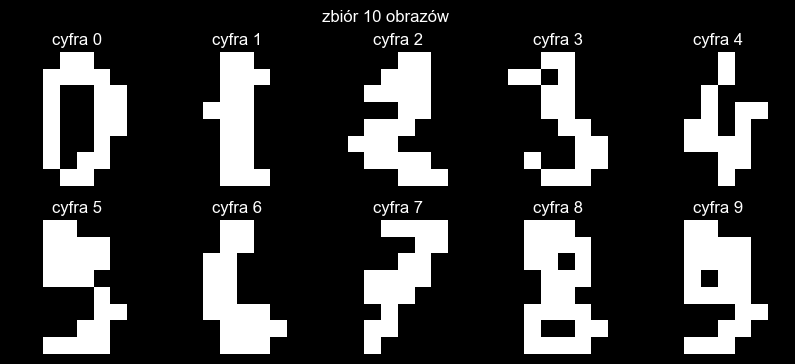

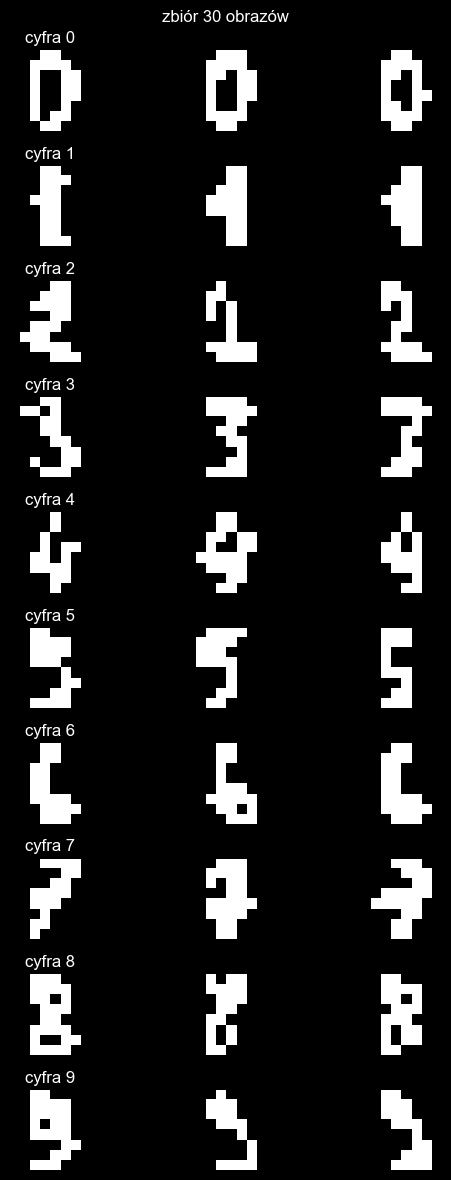

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
Y = digits.target

digits_1 = []
digits_2 = []

for i in range(10):
    number = X[Y == i]
    digits_1.append(number[0])

    for j in range(3):
        digits_2.append(number[j])

digits_1 = np.array(digits_1)
digits_2 = np.array(digits_2)

digits_1 = np.where(digits_1 > 7, 1, -1)
digits_2 = np.where(digits_2 > 7, 1, -1)

def wyswietl_zbior_10(zbior, tytul="zbiór 10 obrazów"):
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    fig.suptitle(tytul)

    for i, ax in enumerate(axes.flat):
        ax.imshow(zbior[i].reshape(8, 8), cmap='gray')
        ax.axis('off')
        ax.set_title(f"cyfra {i}")

    plt.show()

wyswietl_zbior_10(digits_1)

def wyswietl_zbior_30(zbior, tytul="zbiór 30 obrazów"):
    fig, axes = plt.subplots(10, 3, figsize=(6, 12))
    fig.suptitle(tytul)

    for i in range(10):
        for j in range(3):
            indeks = i * 3 + j
            axes[i, j].imshow(zbior[indeks].reshape(8, 8), cmap='gray')
            axes[i, j].axis('off')

            if j == 0:
                axes[i, j].set_title(f"cyfra {i}")

    plt.tight_layout()
    plt.show()

wyswietl_zbior_30(digits_2)

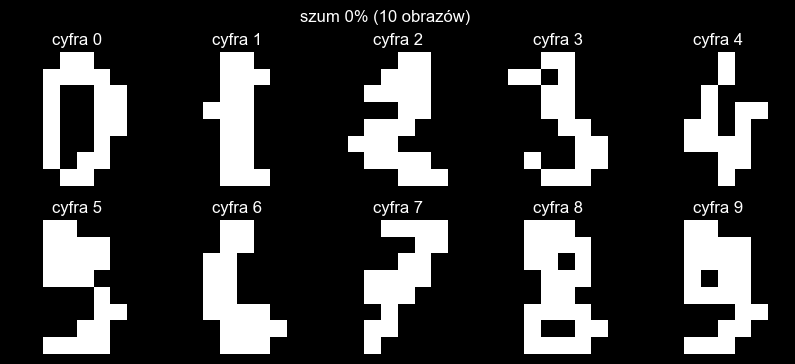

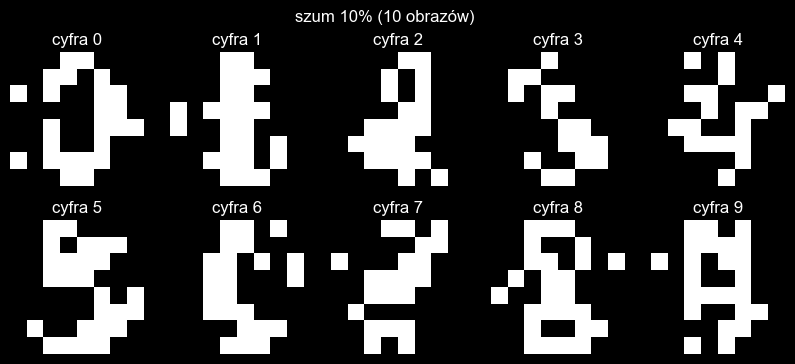

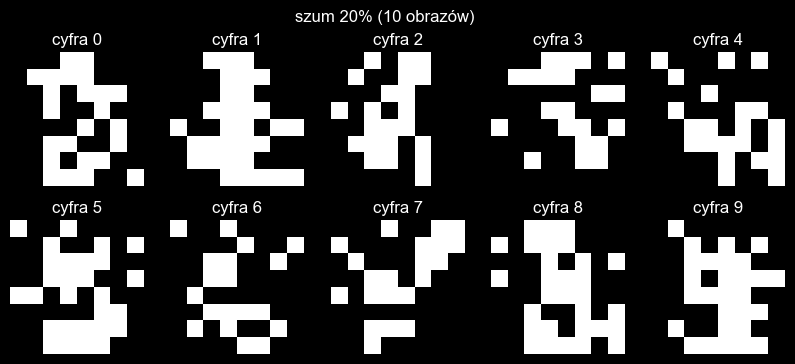

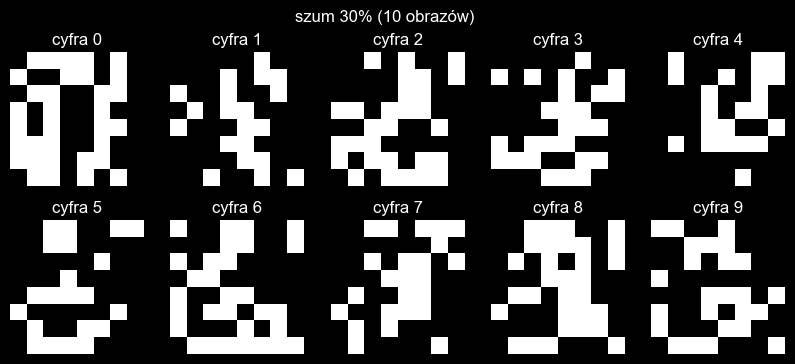

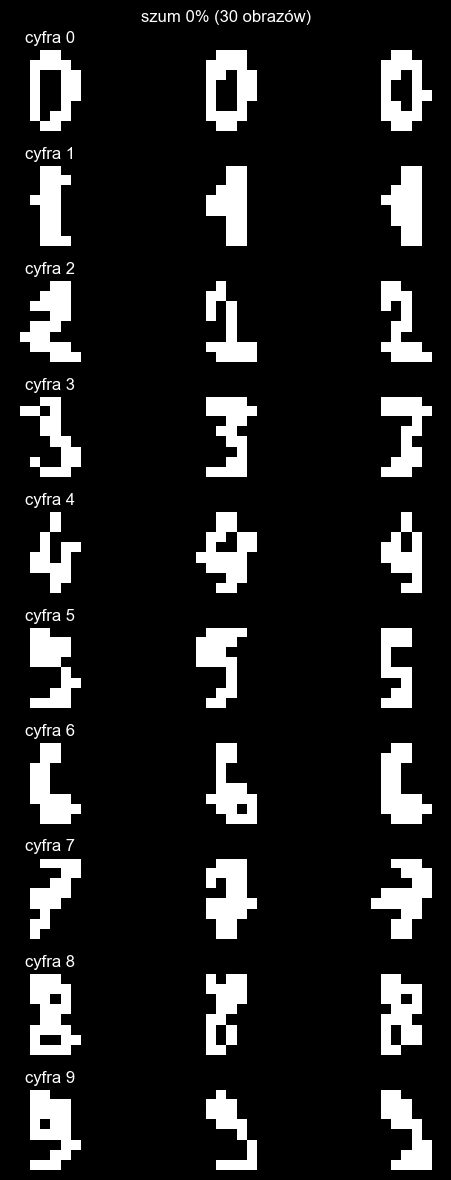

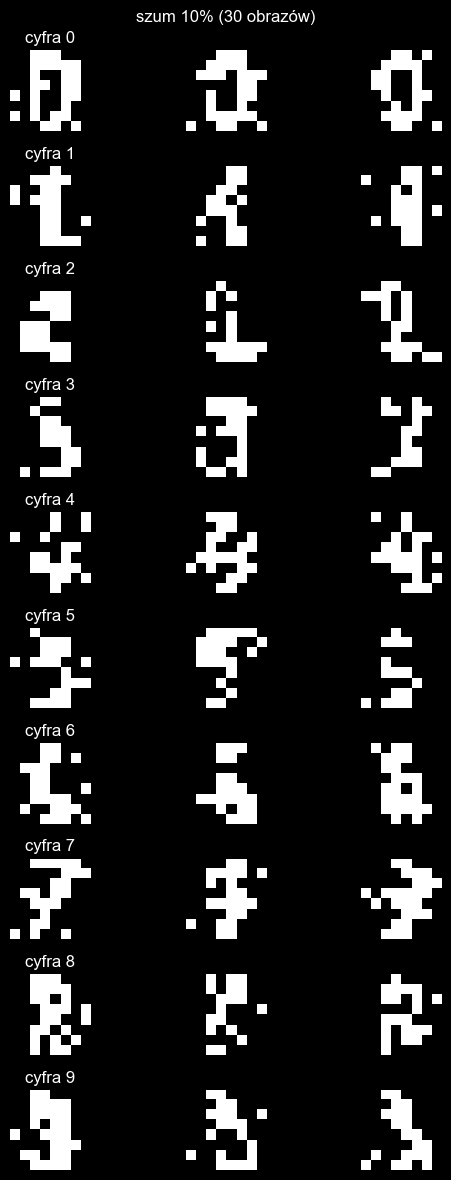

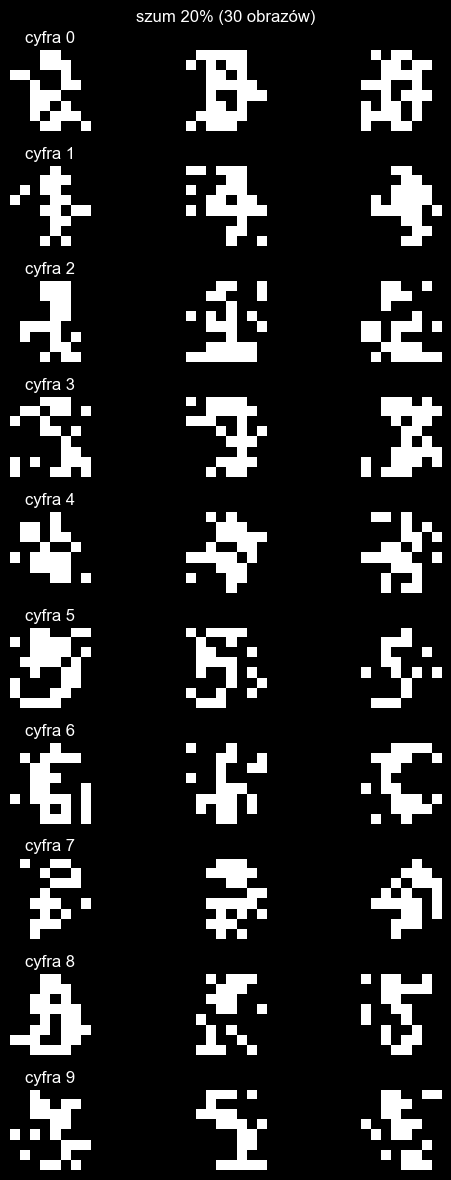

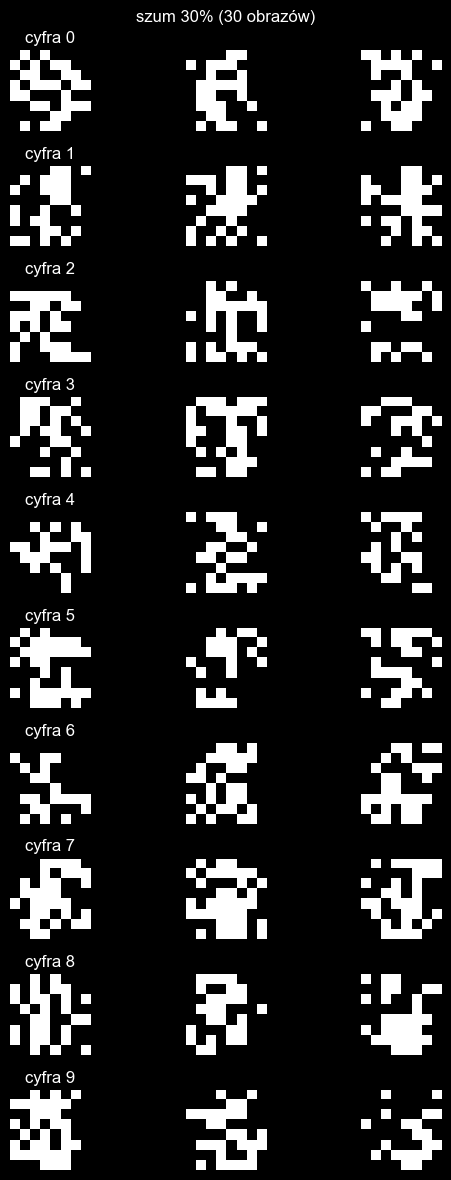

In [2]:
def szum(o, p):
    zaszumiony = np.copy(o)
    liczba_pikseli = int(64 * p)
    indeks = np.random.choice(64, size=liczba_pikseli, replace=False)
    zaszumiony[indeks] *= -1
    return zaszumiony

def zaszum_zbior(z, p):
    zaszumione = [szum(o, p) for o in z]
    return np.array(zaszumione)

wyswietl_zbior_10(digits_1, "szum 0% (10 obrazów)")
digits_1_szum_10 = zaszum_zbior(digits_1, 0.10)
wyswietl_zbior_10(digits_1_szum_10, "szum 10% (10 obrazów)")
digits_1_szum_20 = zaszum_zbior(digits_1, 0.20)
wyswietl_zbior_10(digits_1_szum_20, "szum 20% (10 obrazów)")
digits_1_szum_30 = zaszum_zbior(digits_1, 0.30)
wyswietl_zbior_10(digits_1_szum_30, "szum 30% (10 obrazów)")

wyswietl_zbior_30(digits_2, "szum 0% (30 obrazów)")
digits_2_szum_10 = zaszum_zbior(digits_2, 0.10)
wyswietl_zbior_30(digits_2_szum_10, "szum 10% (30 obrazów)")
digits_2_szum_20 = zaszum_zbior(digits_2, 0.20)
wyswietl_zbior_30(digits_2_szum_20, "szum 20% (30 obrazów)")
digits_2_szum_30 = zaszum_zbior(digits_2, 0.30)
wyswietl_zbior_30(digits_2_szum_30, "szum 30% (30 obrazów)")

Czy macierz wag jest symetryczna? True
Czy na przekątnej znajdują się zera? True
Czy sieć poprawnie zachowuje niezaszumiony wzorzec? True


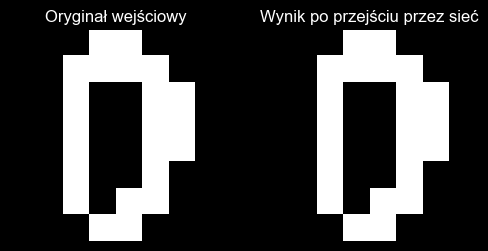

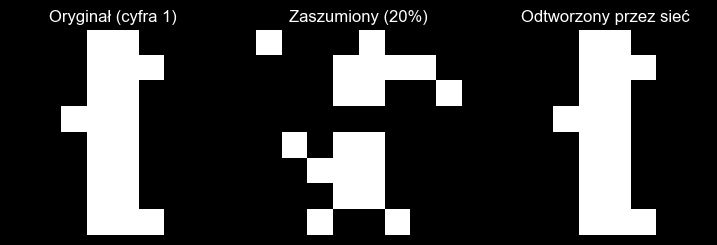

In [3]:
def trenuj_hebba(wzorce):
    P, N = wzorce.shape
    W = np.zeros((N, N))

    for wzorzec in wzorce:
        W += np.outer(wzorzec, wzorzec)

    W = W / P
    np.fill_diagonal(W, 0)
    return W

def aktualizuj_neuron(s, W, i):
    h_i = np.dot(W[i], s)
    if h_i > 0:
        return 1
    elif h_i < 0:
        return -1
    else:
        return s[i]

def odtworz_wzorzec(zaszumiony_obraz, W, max_iter=50):
    s = np.copy(zaszumiony_obraz)
    for _ in range(max_iter):
        s_old = np.copy(s)
        for i in range(len(s)):
            s[i] = aktualizuj_neuron(s, W, i)
        if np.array_equal(s, s_old):
            break
    return s

wzorce_testowe = np.array([digits_1[0], digits_1[1]])
W_10 = trenuj_hebba(wzorce_testowe)

czy_symetryczna = np.allclose(W_10, W_10.T)
print("Czy macierz wag jest symetryczna?", czy_symetryczna)

czy_zera_na_przekatnej = np.all(np.diag(W_10) == 0)
print("Czy na przekątnej znajdują się zera?", czy_zera_na_przekatnej)

oryginal = digits_1[0]

odtworzony_czysty = odtworz_wzorzec(oryginal, W_10)

czy_taki_sam = np.array_equal(oryginal, odtworzony_czysty)
print("Czy sieć poprawnie zachowuje niezaszumiony wzorzec?", czy_taki_sam)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(oryginal.reshape(8, 8), cmap='gray')
axes[0].set_title("Oryginał wejściowy")
axes[0].axis('off')

axes[1].imshow(odtworzony_czysty.reshape(8, 8), cmap='gray')
axes[1].set_title("Wynik po przejściu przez sieć")
axes[1].axis('off')
plt.show()

test_idx = 1
oryginal = digits_1[test_idx]
zaszumiony = szum(oryginal, 0.20)
odtworzony = odtworz_wzorzec(zaszumiony, W_10)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(oryginal.reshape(8, 8), cmap='gray')
axes[0].set_title(f"Oryginał (cyfra {test_idx})")
axes[0].axis('off')

axes[1].imshow(zaszumiony.reshape(8, 8), cmap='gray')
axes[1].set_title("Zaszumiony (20%)")
axes[1].axis('off')

axes[2].imshow(odtworzony.reshape(8, 8), cmap='gray')
axes[2].set_title("Odtworzony przez sieć")
axes[2].axis('off')
plt.show()

Czy macierz wag jest symetryczna? True
Czy na przekątnej znajdują się zera? True


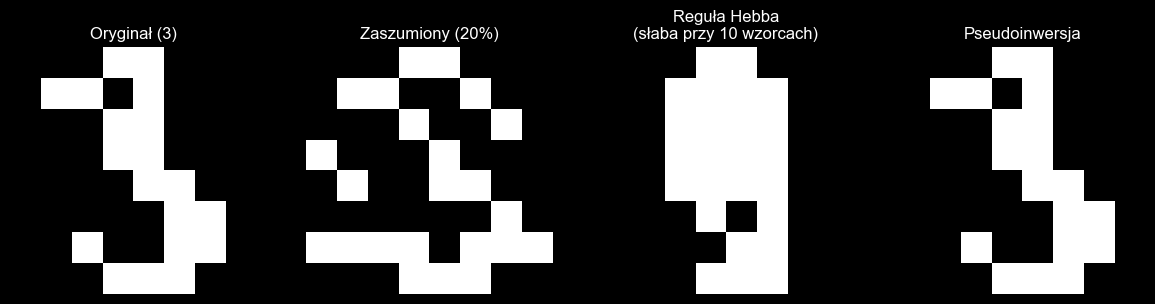

In [21]:
def trenuj_pseudoinwersja(wzorce):
    X = wzorce
    W = np.dot(X.T, np.dot(np.linalg.pinv(np.dot(X, X.T)), X))
    np.fill_diagonal(W, 0)
    return W

W_pseudo = trenuj_pseudoinwersja(digits_1)

czy_symetryczna = np.allclose(W_pseudo, W_pseudo.T)
print("Czy macierz wag jest symetryczna?", czy_symetryczna)

czy_zera_na_przekatnej = np.all(np.diag(W_pseudo) == 0)
print("Czy na przekątnej znajdują się zera?", czy_zera_na_przekatnej)

test_idx = 3
oryginal = digits_1[test_idx]
zaszumiony = szum(oryginal, 0.20)

odtworzony_pseudo = odtworz_wzorzec(zaszumiony, W_pseudo)

W_hebb_10 = trenuj_hebba(digits_1)
odtworzony_hebb = odtworz_wzorzec(zaszumiony, W_hebb_10)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(oryginal.reshape(8, 8), cmap='gray')
axes[0].set_title(f"Oryginał ({test_idx})")
axes[0].axis('off')

axes[1].imshow(zaszumiony.reshape(8, 8), cmap='gray')
axes[1].set_title("Zaszumiony (20%)")
axes[1].axis('off')

axes[2].imshow(odtworzony_hebb.reshape(8, 8), cmap='gray')
axes[2].set_title("Reguła Hebba\n(słaba przy 10 wzorcach)")
axes[2].axis('off')

axes[3].imshow(odtworzony_pseudo.reshape(8, 8), cmap='gray')
axes[3].set_title("Pseudoinwersja")
axes[3].axis('off')

plt.tight_layout()
plt.show()

Czy macierz wag jest symetryczna? True
Czy na przekątnej znajdują się zera? True


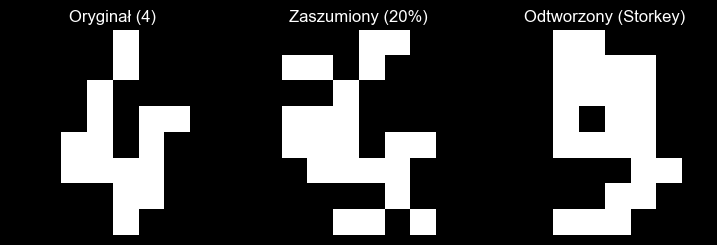

In [20]:
def trenuj_storkey(wzorce):
    P, N = wzorce.shape
    W = np.zeros((N, N))

    for wzorzec in wzorce:
        W_prev = W.copy()
        delta_W = np.zeros((N, N))

        xi = wzorzec.reshape(-1, 1)

        H = np.dot(W_prev, xi)

        for i in range(N):
            for j in range(N):
                if i == j:
                    continue
                h_ij = H[i, 0] - W_prev[i, j] * xi[j, 0]

                delta_W[i, j] = (1.0 / N) * (
                    xi[i, 0] * xi[j, 0]
                    - xi[i, 0] * h_ij
                    - h_ij * xi[j, 0]
                )

        W += delta_W
        W = (W + W.T) / 2

    np.fill_diagonal(W, 0)
    return W

W_storkey = trenuj_storkey(digits_1)

czy_symetryczna = np.allclose(W_storkey, W_storkey.T)
print("Czy macierz wag jest symetryczna?", czy_symetryczna)

czy_zera_na_przekatnej = np.all(np.diag(W_storkey) == 0)
print("Czy na przekątnej znajdują się zera?", czy_zera_na_przekatnej)

test_idx = 4
oryginal = digits_1[test_idx]
zaszumiony = szum(oryginal, 0.20)

odtworzony_storkey = odtworz_wzorzec(zaszumiony, W_storkey)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(oryginal.reshape(8, 8), cmap='gray')
axes[0].set_title(f"Oryginał ({test_idx})")
axes[0].axis('off')

axes[1].imshow(zaszumiony.reshape(8, 8), cmap='gray')
axes[1].set_title("Zaszumiony (20%)")
axes[1].axis('off')

axes[2].imshow(odtworzony_storkey.reshape(8, 8), cmap='gray')
axes[2].set_title("Odtworzony (Storkey)")
axes[2].axis('off')
plt.show()